📌 Fake Reviews Detection
الأبعاد الأصلية: (40432, 4)


,category,rating,label,text_
0,Home_and_Kitchen_5,5.0,CG,"Love this! Well made, sturdy, and very comfor..."
1,Home_and_Kitchen_5,5.0,CG,"love it, a great upgrade from the original. I..."
2,Home_and_Kitchen_5,5.0,CG,This pillow saved my back. I love the look and...
3,Home_and_Kitchen_5,1.0,CG,"Missing information on how to use it, but it i..."
4,Home_and_Kitchen_5,5.0,CG,Very nice set. Good quality. We have had the s...



القيم المفقودة:
 category    0
rating      0
label       0
text_       0
dtype: int64

نصوص مكررة انحذفت: 20
الأبعاد بعد التنظيف: (40412, 6)


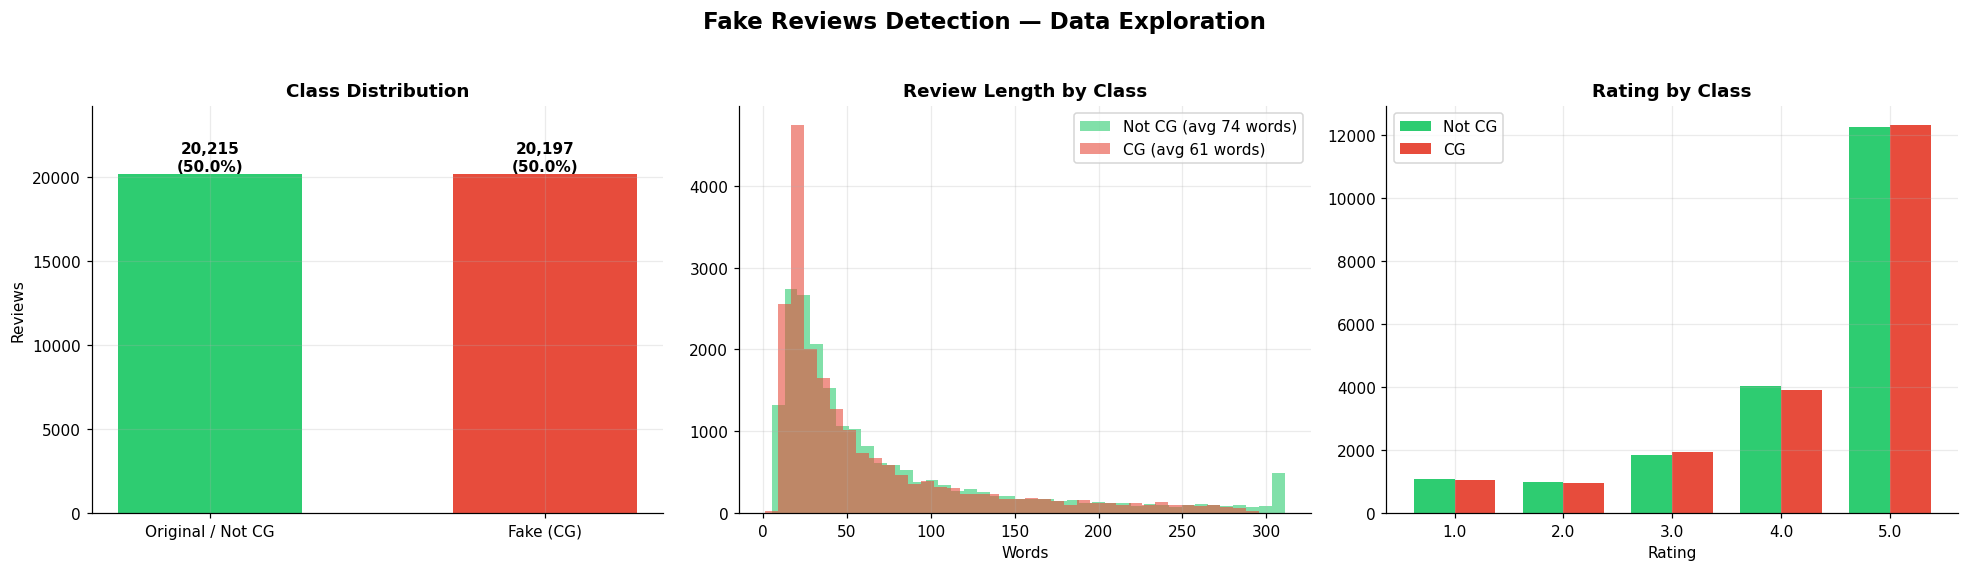

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# ===== ستايل موحد للرسومات =====
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.grid": True, "grid.alpha": 0.25,
})
C_CG, C_OR = "#e74c3c", "#2ecc71"
C_BLUE, C_ORANGE, C_PURPLE, C_GRAY, C_TEAL = "#3498db", "#e67e22", "#9b59b6", "#7f8c8d", "#1abc9c"

PROJECT_NAME = "Fake Reviews Detection"
TARGET_COLUMN = "label"
TEXT_COLUMN = "text_"
file_path = "/Users/rwan/Desktop/fake reviews dataset.csv"

df = pd.read_csv(file_path)
print("📌", PROJECT_NAME)
print("الأبعاد الأصلية:", df.shape)
display(df.head())
print("\nالقيم المفقودة:\n", df.isnull().sum())

# تنظيف
df = df.dropna(subset=[TEXT_COLUMN, TARGET_COLUMN]).reset_index(drop=True)
n_before = len(df)
df = df.drop_duplicates(subset=[TEXT_COLUMN]).reset_index(drop=True)
print("\nنصوص مكررة انحذفت:", n_before - len(df))

df["target"] = (df[TARGET_COLUMN] == "CG").astype(int)   # 1 = مزيف (CG)
df["length"] = df[TEXT_COLUMN].str.split().str.len()
print("الأبعاد بعد التنظيف:", df.shape)

# ===== رسومات الاستكشاف =====
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (أ) توزيع الفئات
vc = df["target"].value_counts().sort_index()
bars = axes[0].bar(["Original / Not CG", "Fake (CG)"], vc.values, color=[C_OR, C_CG], width=0.55)
for b, v in zip(bars, vc.values):
    axes[0].text(b.get_x() + b.get_width()/2, v, f"{v:,}\n({v/len(df):.1%})",
                 ha="center", va="bottom", fontweight="bold")
axes[0].set_ylim(0, vc.max() * 1.2)
axes[0].set_title("Class Distribution")
axes[0].set_ylabel("Reviews")

# (ب) طول المراجعة
cap = df["length"].quantile(0.99)
for t, c, n in [(0, C_OR, "Not CG"), (1, C_CG, "CG")]:
    axes[1].hist(df.loc[df.target == t, "length"].clip(upper=cap), bins=40,
                 alpha=0.6, color=c, label=f"{n} (avg {df.loc[df.target == t, 'length'].mean():.0f} words)")
axes[1].set_title("Review Length by Class")
axes[1].set_xlabel("Words")
axes[1].legend()

# (ج) التقييمات
if "rating" in df.columns:
    ct = pd.crosstab(df["rating"], df["target"])
    ct.plot(kind="bar", ax=axes[2], color=[C_OR, C_CG], width=0.75)
    axes[2].legend(["Not CG", "CG"])
    axes[2].set_title("Rating by Class")
    axes[2].set_xlabel("Rating")
    axes[2].tick_params(axis="x", rotation=0)
else:
    axes[2].axis("off")

plt.suptitle(f"{PROJECT_NAME} — Data Exploration", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()


Train: 28,288 | Test: 8,082 | Val: 4,042


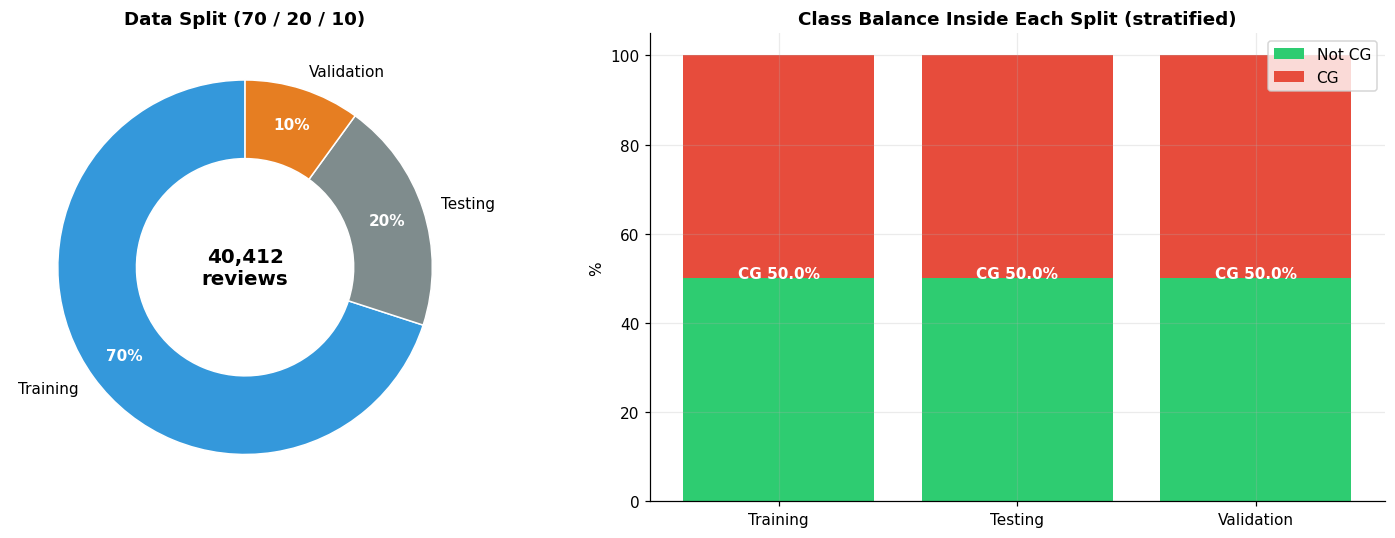

In [2]:
from sklearn.model_selection import train_test_split

X = df[TEXT_COLUMN]
y = df["target"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)
X_test, X_val, y_test, y_val = train_test_split(
    X_temp, y_temp, test_size=1/3, random_state=42, stratify=y_temp)

print(f"Train: {len(X_train):,} | Test: {len(X_test):,} | Val: {len(X_val):,}")

names = ["Training", "Testing", "Validation"]
sizes = [len(X_train), len(X_test), len(X_val)]
ys = [y_train, y_test, y_val]
cols = [C_BLUE, C_GRAY, C_ORANGE]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (أ) دونات الأحجام
wedges, _, autot = axes[0].pie(sizes, labels=names, colors=cols, autopct="%1.0f%%",
                               startangle=90, pctdistance=0.8,
                               wedgeprops=dict(width=0.42, edgecolor="white"))
for t in autot:
    t.set_color("white"); t.set_fontweight("bold")
axes[0].text(0, 0, f"{sum(sizes):,}\nreviews", ha="center", va="center", fontsize=13, fontweight="bold")
axes[0].set_title("Data Split (70 / 20 / 10)")

# (ب) توازن الفئات داخل كل جزء
cg_pct = [yy.mean() * 100 for yy in ys]
axes[1].bar(names, [100 - p for p in cg_pct], color=C_OR, label="Not CG")
axes[1].bar(names, cg_pct, bottom=[100 - p for p in cg_pct], color=C_CG, label="CG")
for i, p in enumerate(cg_pct):
    axes[1].text(i, 50, f"CG {p:.1f}%", ha="center", color="white", fontweight="bold")
axes[1].set_ylabel("%")
axes[1].set_title("Class Balance Inside Each Split (stratified)")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()


Train: (28288, 20000) | Val: (4042, 20000) | Test: (8082, 20000)
Sparsity: 99.85%


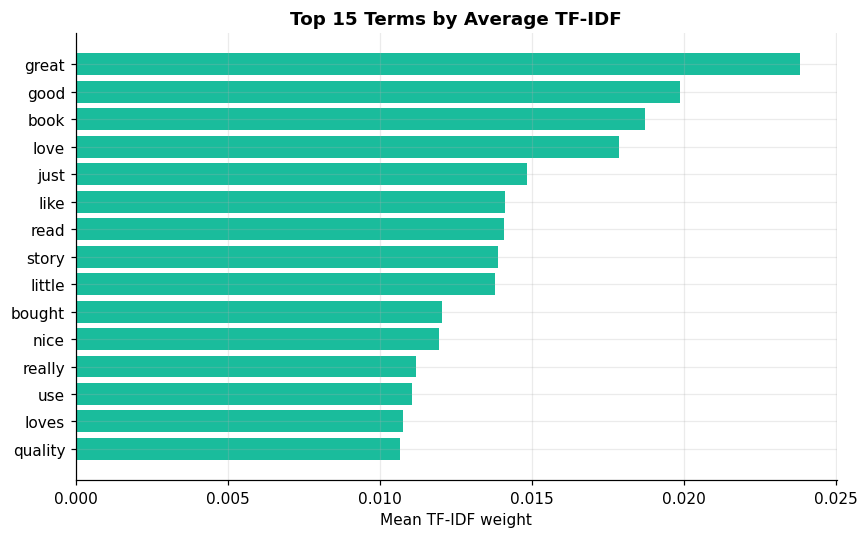

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=20000, ngram_range=(1, 2),
                             min_df=2, sublinear_tf=True, stop_words="english")
X_train_vec = vectorizer.fit_transform(X_train)   # fit على التدريب فقط
X_val_vec = vectorizer.transform(X_val)
X_test_vec = vectorizer.transform(X_test)

assert X_train_vec.shape[0] == len(y_train)
assert X_val_vec.shape[0] == len(y_val)
assert X_test_vec.shape[0] == len(y_test)

sparsity = 1 - X_train_vec.nnz / (X_train_vec.shape[0] * X_train_vec.shape[1])
print(f"Train: {X_train_vec.shape} | Val: {X_val_vec.shape} | Test: {X_test_vec.shape}")
print(f"Sparsity: {sparsity:.2%}")

# أهم 15 كلمة حسب متوسط TF-IDF
terms = vectorizer.get_feature_names_out()
mean_tfidf = np.asarray(X_train_vec.mean(axis=0)).ravel()
top = np.argsort(mean_tfidf)[-15:]

plt.figure(figsize=(8, 5))
plt.barh(terms[top], mean_tfidf[top], color=C_TEAL)
plt.title("Top 15 Terms by Average TF-IDF")
plt.xlabel("Mean TF-IDF weight")
plt.tight_layout()
plt.show()


⏳ Training Logistic Regression ...
⏳ Training Naive Bayes ...
⏳ Training Linear SVM ...
⏳ Training Gradient Boosting ...


,Train Acc,Val Acc,Val F1,Val PR-AUC,Val ROC-AUC,Time (s)
Model,,,,,,
Logistic Regression,0.930000,0.899000,0.899000,0.963000,0.960000,0.212000
Naive Bayes,0.915000,0.888000,0.887000,0.962000,0.959000,0.013000
Linear SVM,0.974000,0.910000,0.910000,0.971000,0.969000,0.355000
Gradient Boosting,0.781000,0.771000,0.751000,0.875000,0.864000,42.082000


Random baseline PR-AUC: 0.5


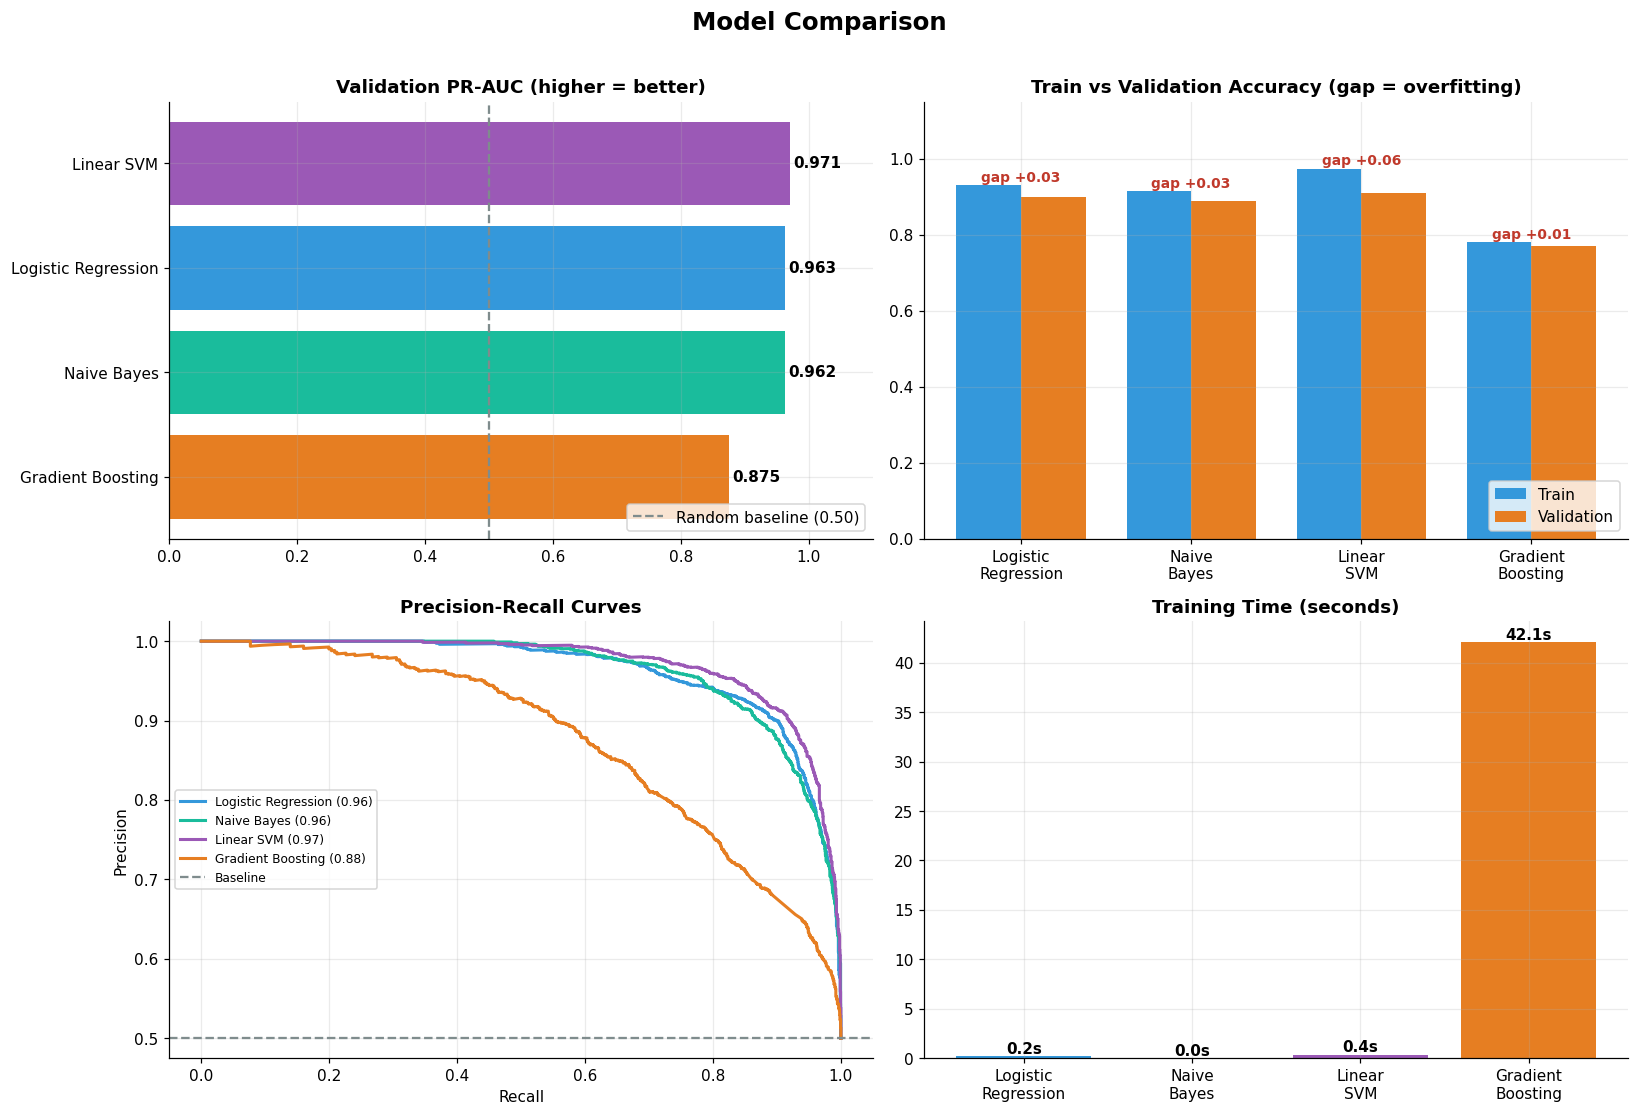

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (average_precision_score, f1_score, roc_auc_score,
                             precision_recall_curve)

MODEL_COLORS = {
    "Logistic Regression": C_BLUE, "Naive Bayes": C_TEAL,
    "Linear SVM": C_PURPLE, "Gradient Boosting": C_ORANGE,
    "Logistic Regression (tuned)": "#2c3e50",
}

models = {
    "Logistic Regression": LogisticRegression(C=1, max_iter=1000, random_state=42),
    "Naive Bayes": MultinomialNB(alpha=0.5),
    "Linear SVM": LinearSVC(C=0.5, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42),
}

def get_scores(m, X):
    return m.predict_proba(X)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(X)

rows, val_scores = [], {}
for name, m in models.items():
    print(f"⏳ Training {name} ...")
    t0 = time.time()
    m.fit(X_train_vec, y_train)
    dur = time.time() - t0
    s = get_scores(m, X_val_vec)
    val_scores[name] = s
    rows.append({
        "Model": name,
        "Train Acc": m.score(X_train_vec, y_train),
        "Val Acc": m.score(X_val_vec, y_val),
        "Val F1": f1_score(y_val, m.predict(X_val_vec)),
        "Val PR-AUC": average_precision_score(y_val, s),
        "Val ROC-AUC": roc_auc_score(y_val, s),
        "Time (s)": dur,
    })

results = pd.DataFrame(rows).set_index("Model")
display(results.round(3).style.background_gradient(
    cmap="Greens", subset=["Val Acc", "Val F1", "Val PR-AUC", "Val ROC-AUC"]))
print("Random baseline PR-AUC:", round(y_val.mean(), 3))

# ===== الرسومات =====
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
order = results["Val PR-AUC"].sort_values().index

# (أ) PR-AUC
ax = axes[0, 0]
bars = ax.barh(order, results.loc[order, "Val PR-AUC"], color=[MODEL_COLORS[m] for m in order])
ax.axvline(y_val.mean(), color=C_GRAY, ls="--", label=f"Random baseline ({y_val.mean():.2f})")
for b in bars:
    ax.text(b.get_width() + 0.005, b.get_y() + b.get_height()/2,
            f"{b.get_width():.3f}", va="center", fontweight="bold")
ax.set_xlim(0, 1.1)
ax.set_title("Validation PR-AUC (higher = better)")
ax.legend(loc="lower right")

# (ب) Train vs Val (Overfitting)
ax = axes[0, 1]
x = np.arange(len(results)); w = 0.38
ax.bar(x - w/2, results["Train Acc"], w, label="Train", color=C_BLUE)
ax.bar(x + w/2, results["Val Acc"], w, label="Validation", color=C_ORANGE)
for i, (tr, va) in enumerate(zip(results["Train Acc"], results["Val Acc"])):
    ax.text(i, max(tr, va) + 0.01, f"gap {tr - va:+.2f}", ha="center", fontsize=9, fontweight="bold", color="#c0392b")
ax.set_xticks(x)
ax.set_xticklabels([n.replace(" ", "\n") for n in results.index])
ax.set_ylim(0, 1.15)
ax.set_title("Train vs Validation Accuracy (gap = overfitting)")
ax.legend(loc="lower right")

# (ج) منحنيات PR
ax = axes[1, 0]
for name in results.index:
    p, r, _ = precision_recall_curve(y_val, val_scores[name])
    ax.plot(r, p, lw=2, color=MODEL_COLORS[name], label=f"{name} ({results.loc[name, 'Val PR-AUC']:.2f})")
ax.axhline(y_val.mean(), color=C_GRAY, ls="--", label="Baseline")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curves")
ax.legend(fontsize=8)

# (د) زمن التدريب
ax = axes[1, 1]
tt = results["Time (s)"]
bars = ax.bar([n.replace(" ", "\n") for n in tt.index], tt.values, color=[MODEL_COLORS[m] for m in tt.index])
for b, v in zip(bars, tt.values):
    ax.text(b.get_x() + b.get_width()/2, v, f"{v:.1f}s", ha="center", va="bottom", fontweight="bold")
ax.set_title("Training Time (seconds)")

plt.suptitle("Model Comparison", fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


📊 Best Parameters: {'C': 10}
📊 Best CV PR-AUC: 0.962
📊 Val PR-AUC: default=0.963 → tuned=0.971


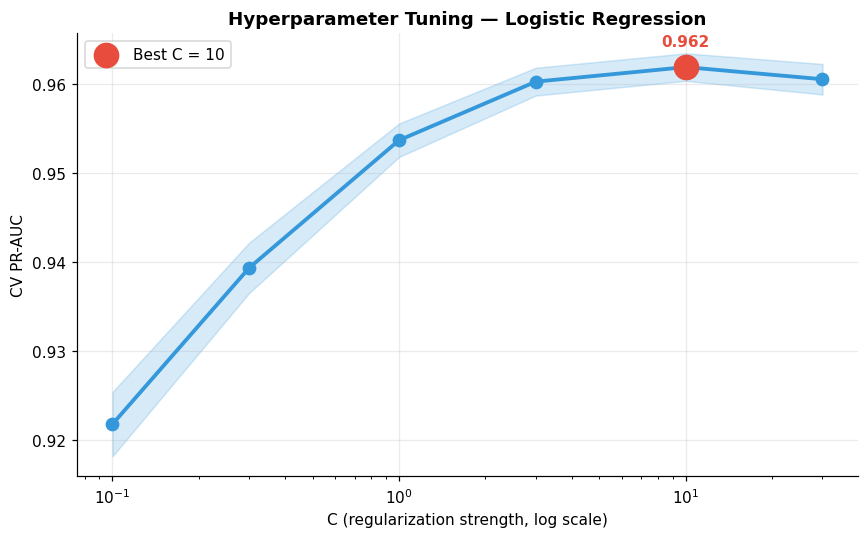

In [5]:
from sklearn.model_selection import GridSearchCV

params = {"C": [0.1, 0.3, 1, 3, 10, 30]}
search = GridSearchCV(LogisticRegression(max_iter=1000, random_state=42),
                      params, scoring="average_precision", cv=3, n_jobs=-1)
search.fit(X_train_vec, y_train)

best_model = search.best_estimator_
models["Logistic Regression (tuned)"] = best_model

cvr = pd.DataFrame(search.cv_results_)
cvr["C"] = cvr["param_C"].astype(float)

default_val = average_precision_score(y_val, get_scores(models["Logistic Regression"], X_val_vec))
tuned_val = average_precision_score(y_val, get_scores(best_model, X_val_vec))
print("📊 Best Parameters:", search.best_params_)
print("📊 Best CV PR-AUC:", round(search.best_score_, 3))
print(f"📊 Val PR-AUC: default={default_val:.3f} → tuned={tuned_val:.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(cvr["C"], cvr["mean_test_score"], "o-", color=C_BLUE, lw=2.5, ms=8)
ax.fill_between(cvr["C"],
                cvr["mean_test_score"] - cvr["std_test_score"],
                cvr["mean_test_score"] + cvr["std_test_score"], color=C_BLUE, alpha=0.2)
bc = search.best_params_["C"]
ax.scatter([bc], [search.best_score_], s=250, color=C_CG, zorder=5, label=f"Best C = {bc}")
ax.annotate(f"{search.best_score_:.3f}", (bc, search.best_score_), textcoords="offset points",
            xytext=(0, 14), ha="center", fontweight="bold", color=C_CG)
ax.set_xscale("log")
ax.set_xlabel("C (regularization strength, log scale)")
ax.set_ylabel("CV PR-AUC")
ax.set_title("Hyperparameter Tuning — Logistic Regression")
ax.legend()
plt.tight_layout()
plt.show()


🎯 Threshold: 0.5
📊 PR-AUC: 0.969 | ROC-AUC: 0.966
📊 Precision: 0.897 | Recall: 0.900 | F1: 0.899 | Accuracy: 0.899
📋 Confusion Matrix:
 [[3627  416]
 [ 403 3636]]
💡 أفضل threshold حسب F1: 0.43 (F1 = 0.901)


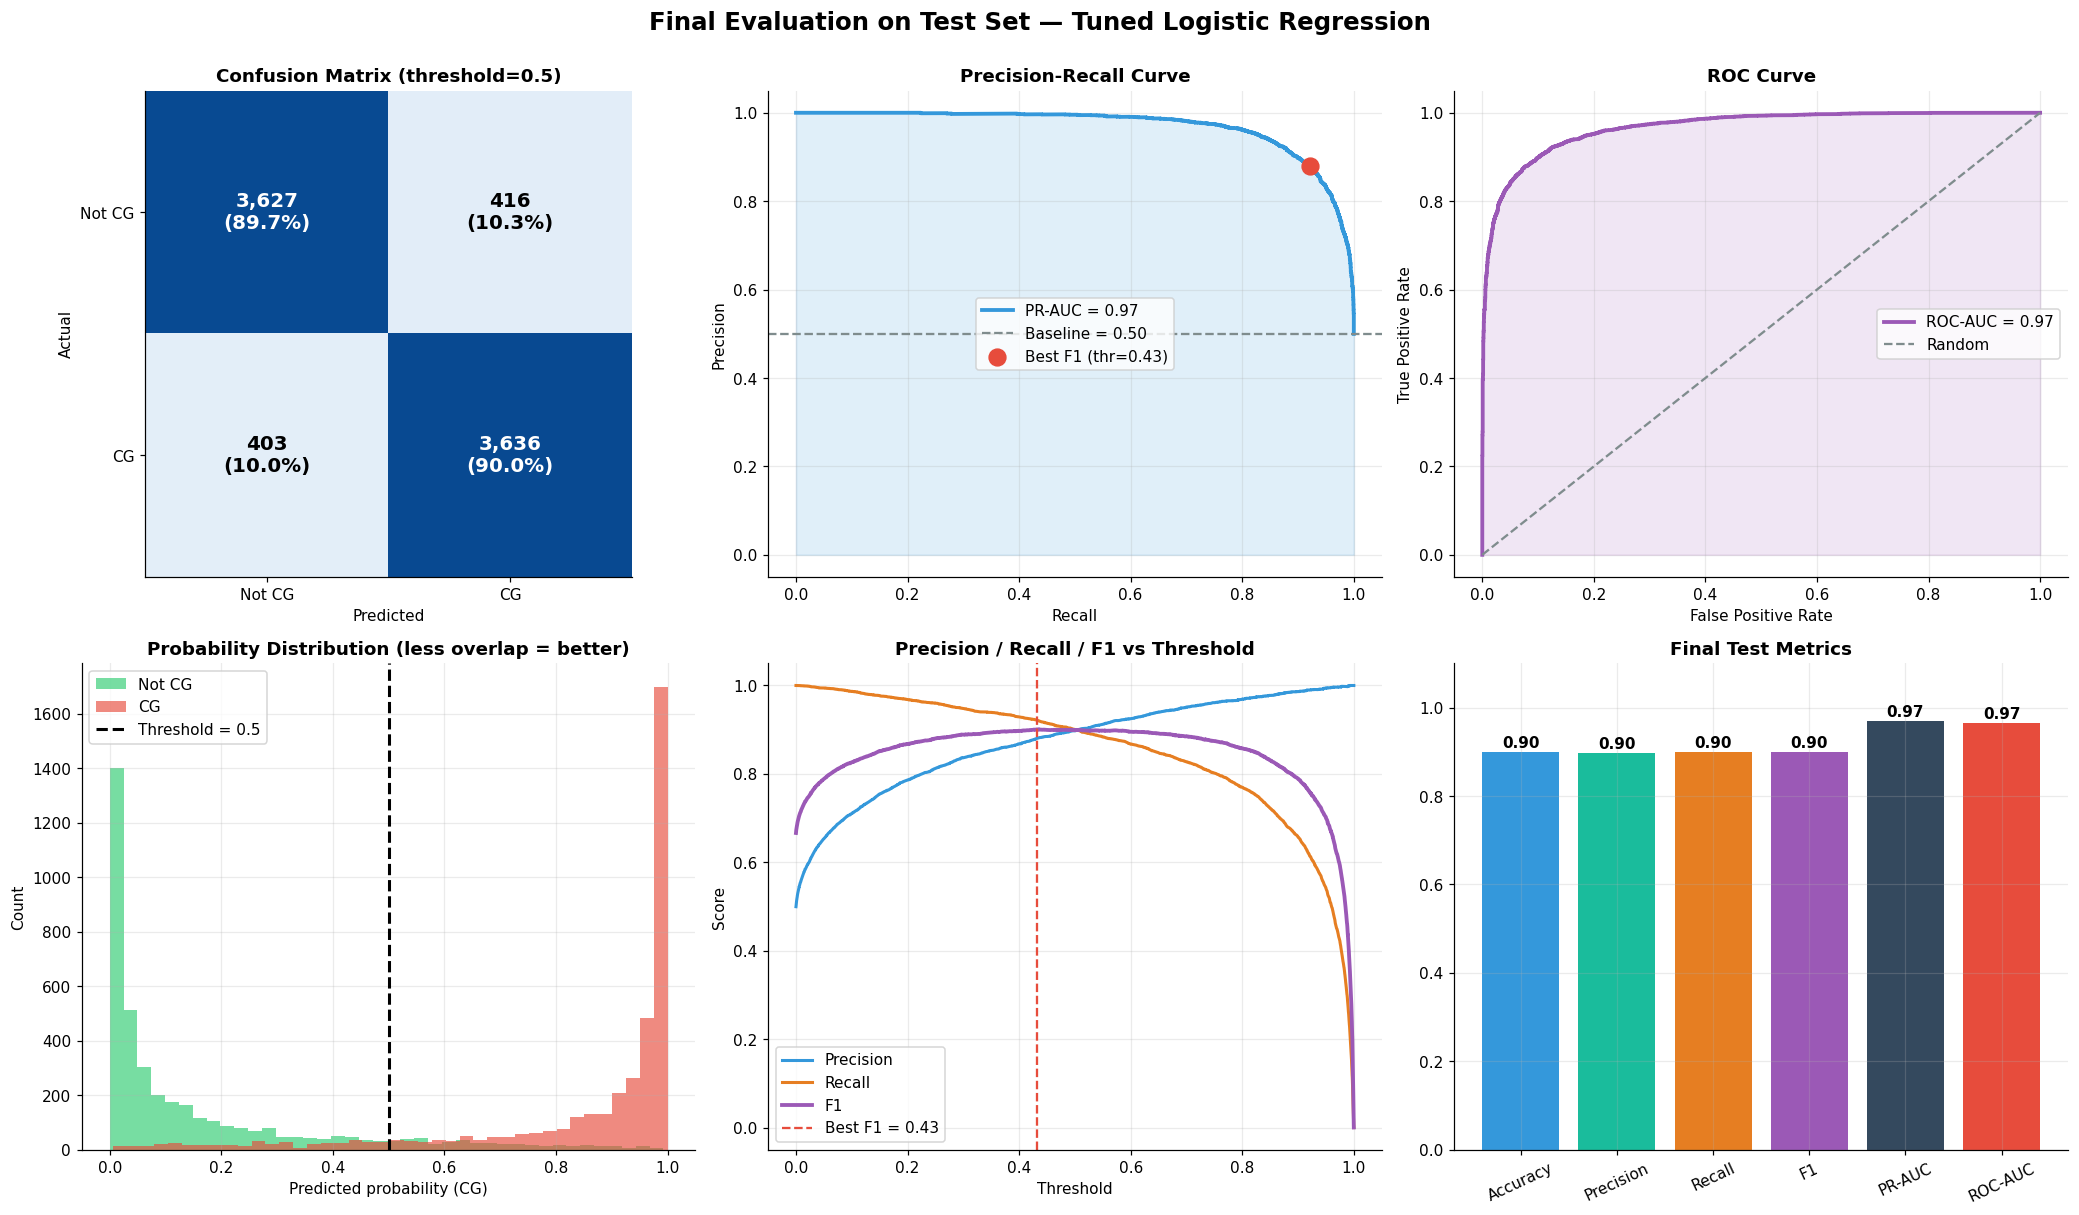

✅ Done!


In [6]:
from sklearn.metrics import (confusion_matrix, precision_recall_curve, roc_curve,
                             precision_score, recall_score, accuracy_score)

probabilities = best_model.predict_proba(X_test_vec)[:, 1]
y_true = np.array(y_test)
threshold = 0.5
predictions = (probabilities >= threshold).astype(int)

pr_auc = average_precision_score(y_true, probabilities)
roc_auc = roc_auc_score(y_true, probabilities)
f1 = f1_score(y_true, predictions)
prec = precision_score(y_true, predictions, zero_division=0)
rec = recall_score(y_true, predictions)
acc = accuracy_score(y_true, predictions)
cm = confusion_matrix(y_true, predictions)

print(f"🎯 Threshold: {threshold}")
print(f"📊 PR-AUC: {pr_auc:.3f} | ROC-AUC: {roc_auc:.3f}")
print(f"📊 Precision: {prec:.3f} | Recall: {rec:.3f} | F1: {f1:.3f} | Accuracy: {acc:.3f}")
print("📋 Confusion Matrix:\n", cm)

precision, recall, thr = precision_recall_curve(y_true, probabilities)
f1s = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-9)
bi = np.argmax(f1s)
print(f"💡 أفضل threshold حسب F1: {thr[bi]:.2f} (F1 = {f1s[bi]:.3f})")

fig, axes = plt.subplots(2, 3, figsize=(19, 11))

# (1) Confusion Matrix
ax = axes[0, 0]
cm_pct = cm / cm.sum(axis=1, keepdims=True)
ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n({cm_pct[i, j]:.1%})", ha="center", va="center",
                fontsize=13, fontweight="bold", color="white" if cm_pct[i, j] > 0.5 else "black")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Not CG", "CG"]); ax.set_yticklabels(["Not CG", "CG"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title(f"Confusion Matrix (threshold={threshold})")
ax.grid(False)

# (2) PR curve
ax = axes[0, 1]
ax.plot(recall, precision, color=C_BLUE, lw=2.5, label=f"PR-AUC = {pr_auc:.2f}")
ax.fill_between(recall, precision, alpha=0.15, color=C_BLUE)
ax.axhline(y_true.mean(), color=C_GRAY, ls="--", label=f"Baseline = {y_true.mean():.2f}")
ax.scatter(recall[bi], precision[bi], s=120, color=C_CG, zorder=5, label=f"Best F1 (thr={thr[bi]:.2f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curve")
ax.legend()

# (3) ROC
ax = axes[0, 2]
fpr, tpr, _ = roc_curve(y_true, probabilities)
ax.plot(fpr, tpr, color=C_PURPLE, lw=2.5, label=f"ROC-AUC = {roc_auc:.2f}")
ax.fill_between(fpr, tpr, alpha=0.15, color=C_PURPLE)
ax.plot([0, 1], [0, 1], color=C_GRAY, ls="--", label="Random")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve")
ax.legend()

# (4) توزيع الاحتمالات
ax = axes[1, 0]
ax.hist(probabilities[y_true == 0], bins=40, alpha=0.65, color=C_OR, label="Not CG")
ax.hist(probabilities[y_true == 1], bins=40, alpha=0.65, color=C_CG, label="CG")
ax.axvline(threshold, color="black", ls="--", lw=2, label=f"Threshold = {threshold}")
ax.set_xlabel("Predicted probability (CG)"); ax.set_ylabel("Count")
ax.set_title("Probability Distribution (less overlap = better)")
ax.legend()

# (5) Precision / Recall / F1 vs Threshold
ax = axes[1, 1]
ax.plot(thr, precision[:-1], color=C_BLUE, lw=2, label="Precision")
ax.plot(thr, recall[:-1], color=C_ORANGE, lw=2, label="Recall")
ax.plot(thr, f1s, color=C_PURPLE, lw=2.5, label="F1")
ax.axvline(thr[bi], color=C_CG, ls="--", label=f"Best F1 = {thr[bi]:.2f}")
ax.set_xlabel("Threshold"); ax.set_ylabel("Score")
ax.set_title("Precision / Recall / F1 vs Threshold")
ax.legend()

# (6) ملخص المقاييس
ax = axes[1, 2]
mnames = ["Accuracy", "Precision", "Recall", "F1", "PR-AUC", "ROC-AUC"]
mvals = [acc, prec, rec, f1, pr_auc, roc_auc]
bars = ax.bar(mnames, mvals, color=[C_BLUE, C_TEAL, C_ORANGE, C_PURPLE, "#34495e", C_CG])
for b, v in zip(bars, mvals):
    ax.text(b.get_x() + b.get_width()/2, v + 0.01, f"{v:.2f}", ha="center", fontweight="bold")
ax.set_ylim(0, 1.1)
ax.set_title("Final Test Metrics")
ax.tick_params(axis="x", rotation=25)

plt.suptitle("Final Evaluation on Test Set — Tuned Logistic Regression", fontsize=16, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()
print("✅ Done!")


,PR-AUC,ROC-AUC,F1,Accuracy
Model,,,,
Logistic Regression,0.963000,0.960000,0.888000,0.889000
Naive Bayes,0.960000,0.956000,0.877000,0.878000
Linear SVM,0.970000,0.967000,0.902000,0.902000
Gradient Boosting,0.881000,0.867000,0.760000,0.780000
Logistic Regression (tuned),0.969000,0.966000,0.899000,0.899000


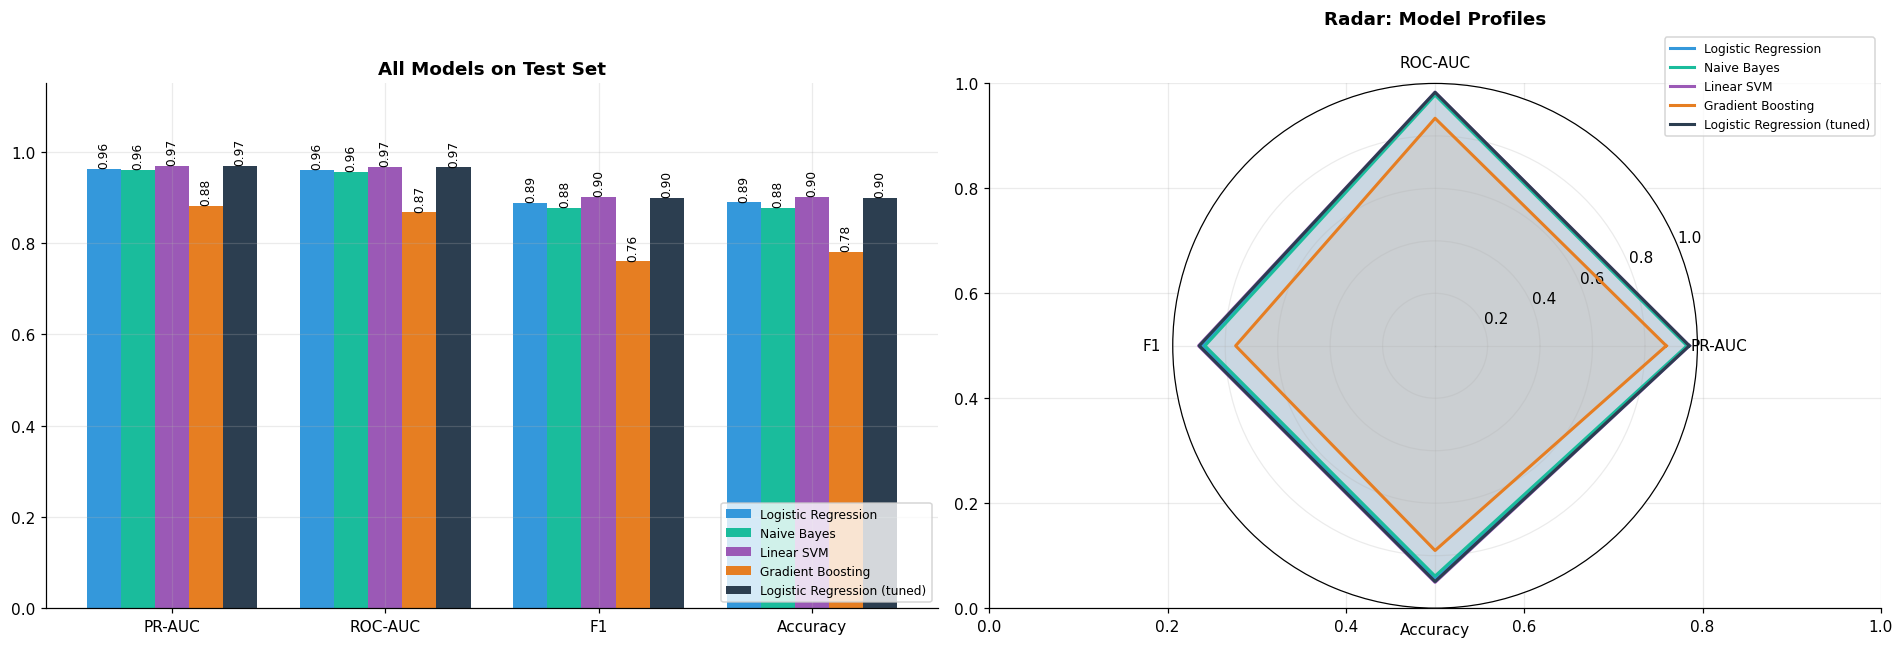

In [7]:
rows = []
test_scores = {}
for name, m in models.items():
    s = get_scores(m, X_test_vec)
    test_scores[name] = s
    rows.append({
        "Model": name,
        "PR-AUC": average_precision_score(y_test, s),
        "ROC-AUC": roc_auc_score(y_test, s),
        "F1": f1_score(y_test, m.predict(X_test_vec)),
        "Accuracy": m.score(X_test_vec, y_test),
    })
final_df = pd.DataFrame(rows).set_index("Model")
display(final_df.round(3).style.background_gradient(cmap="YlGn"))

metrics = ["PR-AUC", "ROC-AUC", "F1", "Accuracy"]
x = np.arange(len(metrics))
w = 0.8 / len(final_df)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# (أ) أعمدة مجمّعة
ax = axes[0]
for i, name in enumerate(final_df.index):
    vals = final_df.loc[name, metrics].values
    bars = ax.bar(x + i*w - 0.4 + w/2, vals, w, label=name, color=MODEL_COLORS[name])
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 0.008, f"{v:.2f}", ha="center", fontsize=8, rotation=90)
ax.set_xticks(x); ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.15)
ax.set_title("All Models on Test Set")
ax.legend(fontsize=8, loc="lower right")

# (ب) Radar
ax = plt.subplot(1, 2, 2, polar=True)
angles = np.linspace(0, 2*np.pi, len(metrics), endpoint=False).tolist()
angles += angles[:1]
for name in final_df.index:
    vals = final_df.loc[name, metrics].tolist()
    vals += vals[:1]
    ax.plot(angles, vals, lw=2, color=MODEL_COLORS[name], label=name)
    ax.fill(angles, vals, alpha=0.08, color=MODEL_COLORS[name])
ax.set_xticks(angles[:-1]); ax.set_xticklabels(metrics)
ax.set_ylim(0, 1)
ax.set_title("Radar: Model Profiles", pad=20, fontweight="bold")
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1), fontsize=8)

plt.tight_layout()
plt.show()


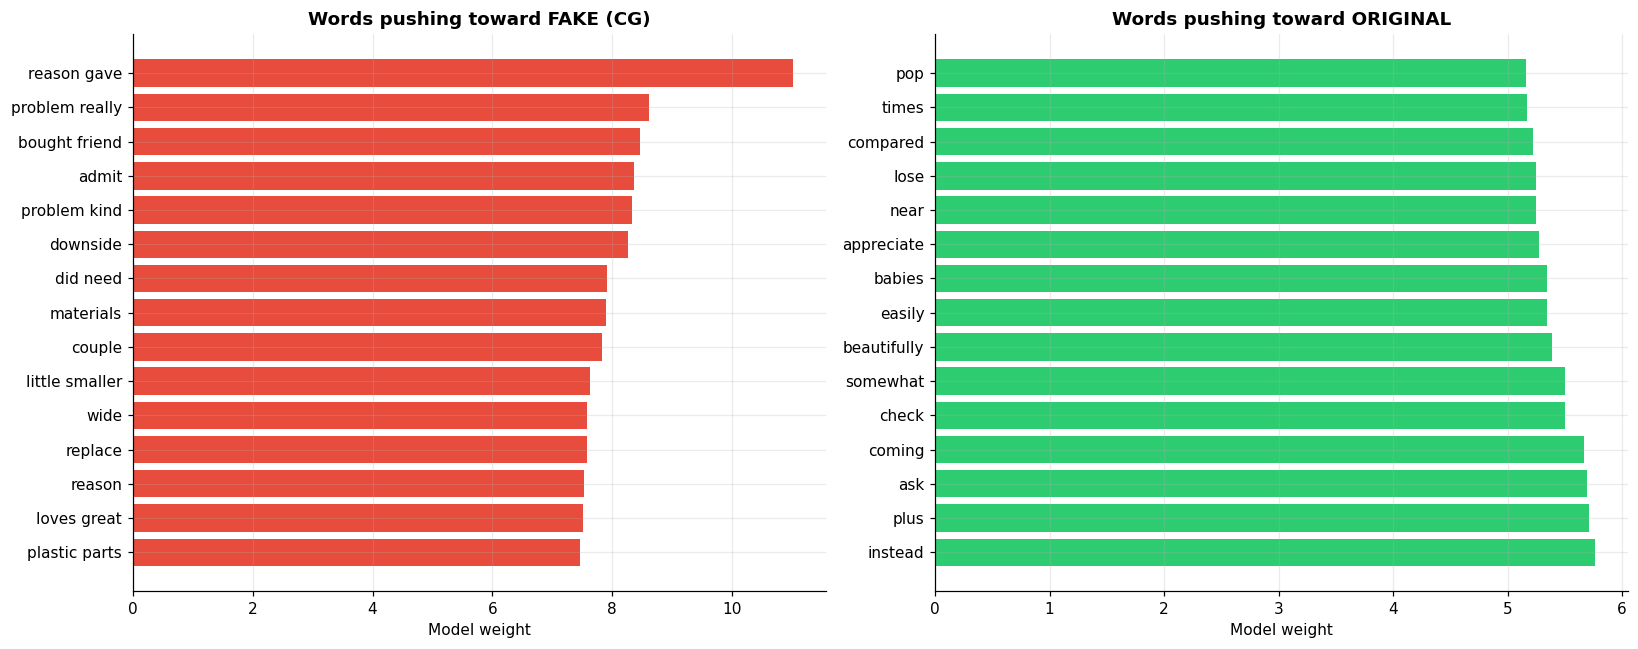


❌ مراجعات أصلية حكم عليها كمزيفة:
  [0.99] These are very nice! No bulbs to replace and are bright and work well. Look great too....
  [0.99] This is a good movie.  Not just about Bobby but also about some history of golf and Augusta....
  [0.99] this is a strong and great movie the acting is well done it is a well made movie...

❌ مراجعات مزيفة حكم عليها كأصلية:
  [0.01] Installed toshiba bluetooth stack like a charm, and it works perfectly.  I have a few friends who have two...
  [0.01] These table extensions really do what they are suppose to do.

The table extension does not extend the base of the table plate, wh...
  [0.01] what i wanted
great quality
check out some of the other reviews

and i hope i got this one.I bought this for...


In [8]:
coefs = best_model.coef_[0]
feat = vectorizer.get_feature_names_out()
top_cg = np.argsort(coefs)[-15:]
top_or = np.argsort(coefs)[:15]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(feat[top_cg], coefs[top_cg], color=C_CG)
axes[0].set_title("Words pushing toward FAKE (CG)")
axes[1].barh(feat[top_or], np.abs(coefs[top_or]), color=C_OR)
axes[1].set_title("Words pushing toward ORIGINAL")
for a in axes:
    a.set_xlabel("Model weight")
plt.tight_layout()
plt.show()

# أخطاء النموذج الأكثر ثقة
test_df = pd.DataFrame({"text": X_test.values, "true": y_test.values,
                        "prob": probabilities, "pred": predictions})
fp = test_df[(test_df.true == 0) & (test_df.pred == 1)].sort_values("prob", ascending=False).head(3)
fn = test_df[(test_df.true == 1) & (test_df.pred == 0)].sort_values("prob").head(3)

print("\n❌ مراجعات أصلية حكم عليها كمزيفة:")
for _, r in fp.iterrows():
    print(f"  [{r.prob:.2f}] {r.text[:130]}...")
print("\n❌ مراجعات مزيفة حكم عليها كأصلية:")
for _, r in fn.iterrows():
    print(f"  [{r.prob:.2f}] {r.text[:130]}...")
